# 2-D flat metalens — cross-section
A 2-D (x, y) cross-section of a flat focusing lens. The domain is one voxel thick in
z and periodic there (a true 2-D solve). Polarization is z (TM, E_z) —
z is the invariant direction, so E is transverse to the +x propagation. The full field is
saved to metalens_2d_field.npy so the focus can be inspected numerically
(peak location, beam width, spot FWHM).

Size: 0.516 Mvoxel including boundaries, 0.027 GB of memory (service estimate).

Realization: blazed surface-relief (kinoform)
---------------------------------------------
The lens imprints the hyperbolic focusing phase as a **surface-relief height
profile** of solid high-index material (TiO₂) on a glass substrate. At transverse
position y the relief is h(y) tall, so the transmitted phase is the optical path
through the material,

    φ(y) = k₀ · (n − 1) · h(y),   wrapped so h ∈ [0, λ/(n−1)) spans a full 2π,

set to the hyperbolic lens phase φ(r) = sign·k₀(√(r²+f²) − f) wrapped to [0, 2π).
The material is solid and fully resolved (no sub-wavelength features, no
effective-medium approximation), so the phase is physically imprinted and the lens
focuses to a diffraction-limited spot. A surface relief is the simplest realization
in 2-D.

Outputs (in output/mx_metalens_2d/):
  * metalens_2d_field.png   — the X–Y |E| map (focal cone);
  * metalens_2d_field.npy   — full |E| field (nx, ny) for numerical checks.

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

from wsutils import apodise, output_dir
from wavesimpro import configure, simulate

NAME = "mx_metalens_2d"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME)

### Parameters

In [2]:
wavelength = 0.532   # μm, green, in air
pixel_size = 0.03    # μm (~λ/17.7 in air; resolves the relief, ~13 voxels tall)

n_lens = 2.4         # TiO₂-like relief index
n_substrate = 1.5    # glass substrate
n_bg = 1.0           # air

aperture = 10.0       # aperture extent in Y, μm
focal_length = 12.0   # design focal length from the relief exit plane, μm

# Sign of the focusing phase φ(r) = sign·k₀(√(r²+f²)−f). −1 is the focusing sign
# (standard convention): a converging phase with sign=−1 collapses to a focus a
# distance f beyond the lens; sign=+1 diverges.
focusing_sign = -1.0

k0 = 2 * np.pi / wavelength
max_height = wavelength / (n_lens - 1)  # relief height spanning a full 2π, μm

NA = (aperture / 2) / np.sqrt((aperture / 2) ** 2 + focal_length ** 2)
dl_fwhm = 0.51 * wavelength / NA  # diffraction-limited FWHM, μm (order-of-magnitude in 2-D)

# Domain along X: air gap → substrate → relief layer (≤ max_height) → air focus.
x_src = 0.6
x_sub0 = 1.0
t_substrate = 1.5
x_relief0 = x_sub0 + t_substrate          # relief base (on the substrate), μm
x_relief1 = x_relief0 + max_height         # tallest the relief can be, μm
x_focus = x_relief1 + focal_length         # design focus depth, μm
x_end = x_focus + 3.0
transverse = aperture + 5.0  # Y extent, μm

sim_size = np.array([x_end, transverse])
n_size = (sim_size / pixel_size).astype(int)
nx, ny = int(n_size[0]), int(n_size[1])
cy = transverse / 2

taper = 0.3

print(f"2-D domain {sim_size} μm = {nx}x{ny} voxels ({nx * ny / 1e6:.2f} Mvoxel without boundaries, z-periodic)")
print(f"Metalens: aperture {aperture} μm, f = {focal_length} μm, NA = {NA:.2f}; "
      f"DL FWHM ≈ {dl_fwhm * 1000:.0f} nm; focus x ≈ {x_focus:.1f} μm")
print(f"Relief: n={n_lens}, height 0…{max_height:.3f} μm (~{max_height / pixel_size:.0f} voxels, full 2π)")

2-D domain [17.88 15.  ] μm = 596x500 voxels (0.30 Mvoxel without boundaries, z-periodic)
Metalens: aperture 10.0 μm, f = 12.0 μm, NA = 0.38; DL FWHM ≈ 705 nm; focus x ≈ 14.9 μm
Relief: n=2.4, height 0…0.380 μm (~13 voxels, full 2π)


### Medium: substrate + blazed surface-relief lens (n², shape (nx, ny, 1))

In [3]:
def build_metalens_2d():
    n = np.full((nx, ny), n_bg, dtype=np.complex64)
    x = np.arange(nx) * pixel_size
    y = np.arange(ny) * pixel_size

    n[(x >= x_sub0) & (x < x_relief0), :] = n_substrate

    # Hyperbolic focusing phase wrapped to [0, 2π) → relief height per column.
    r = y - cy
    in_ap = np.abs(r) <= aperture / 2
    phase = np.mod(focusing_sign * k0 * (np.sqrt(r ** 2 + focal_length ** 2) - focal_length),
                   2 * np.pi)
    h = phase / (k0 * (n_lens - 1))  # height for that phase, μm
    h[~in_ap] = 0.0

    ix0 = int(x_relief0 / pixel_size)
    for iy in range(ny):
        ih = int(round(h[iy] / pixel_size))
        if ih > 0:
            n[ix0:ix0 + ih, iy] = n_lens

    print(f"Relief built across the {aperture} μm aperture "
          f"(height range {h[in_ap].min():.3f}…{h[in_ap].max():.3f} μm)")
    return (n ** 2).astype(np.complex64)[..., None]  # (nx, ny, 1)


permittivity = build_metalens_2d()

Relief built across the 10.0 μm aperture (height range 0.000…0.380 μm)


### Source: z-polarized (TM) plane wave along Y at x_src

In [4]:
# Tukey-tapered sheet across Y so it does not diffract off the absorbing walls.
# Axis order is (polarization, x, y, z): a Y-spanning sheet at one x-plane is
# (1, 1, ny, 1). position (polarization=z, x, y, z) in pixels.
source_values = np.ones((1, 1, ny, 1), dtype=np.complex64)
source_position = (2, int(x_src / pixel_size), 0, 0)
source_values, source_position = apodise((source_values, source_position),
                                         axes="y", alpha=taper)

### Solve

In [5]:
print("\nRunning 2-D simulation...")
start = time()
u, iterations, residual_norm = simulate(
    permittivity=permittivity,
    sources=[(source_values, source_position)],
    wavelength=wavelength,
    pixel_size=pixel_size,
    boundary_width=2.5,  # absorbing boundary width, μm (≈5 λ)
    periodic=(False, False, True),  # periodic z → 2-D
)
print(f"Time {time() - start:.1f} s; Iterations {iterations}; Residual {residual_norm:.2e}")

u = np.asarray(u)  # vector field, (3, nx, ny) in 2-D (singleton z dropped)
intensity = (np.abs(u) ** 2).sum(axis=0)  # |E|²
if intensity.ndim == 3:  # if the z axis survives, take the central plane
    intensity = intensity[:, :, intensity.shape[2] // 2]
amp = np.sqrt(intensity)
print(f"|E| max = {amp.max():.3e}; mean = {amp.mean():.3e}")

# Save the full field for numerical inspection (small in 2-D).
np.save(f"{OUTPUT_DIR}/metalens_2d_field.npy", amp.astype(np.float32))

# Locate the on-axis focus in the air region beyond the relief.
iy_c = ny // 2
axis_band = intensity[:, iy_c - 1:iy_c + 2].mean(axis=1)
ix_air0 = int((x_relief1 + 0.5) / pixel_size)
ix_focus = ix_air0 + int(np.argmax(axis_band[ix_air0:]))
print(f"Brightest on-axis point beyond relief: x = {ix_focus * pixel_size:.2f} μm "
      f"(design focus {x_focus:.2f} μm)")


Running 2-D simulation...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 9ab4fef6-4212-496d-ad82-9e1c4bf6e0b0
  Version   : 232384eb-3579-464d-bf26-ba0343fd1449
  Command   : 2c2a07d2-cf4d-4497-8c2a-52f9d9ea3c77
  Mode      : Maxwell (vectorial)
  Domain    : 596x500x1 voxels  lambda=0.532 um  dx=0.030 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Time 43.5 s; Iterations 813; Residual 9.78e-07
|E| max = 4.045e-03; mean = 8.629e-04
Brightest on-axis point beyond relief: x = 14.37 μm (design focus 14.88 μm)


### Figure: X–Y |E| map

Saved output/mx_metalens_2d/metalens_2d_field.png and metalens_2d_field.npy


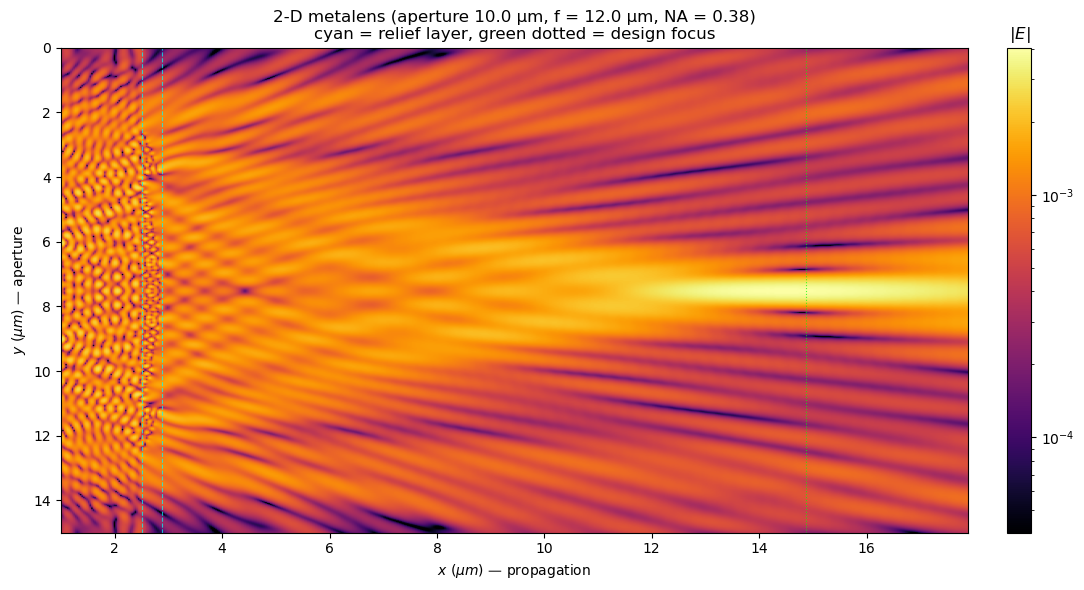

In [6]:
vmax = amp.max()
vmin = vmax * 1e-2
extent = [0, nx * pixel_size, ny * pixel_size, 0]
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(amp.T, cmap="inferno", extent=extent,
               norm=colors.LogNorm(vmin=vmin, vmax=vmax), aspect="auto")
ax.axvline(x_relief0, color="cyan", lw=0.8, ls="--", alpha=0.7)
ax.axvline(x_relief1, color="cyan", lw=0.8, ls="--", alpha=0.7)
ax.axvline(x_focus, color="lime", lw=0.8, ls=":", alpha=0.7)
ax.set_xlim(x_sub0, nx * pixel_size)
ax.set_xlabel(r"$x~(\mu m)$ — propagation")
ax.set_ylabel(r"$y~(\mu m)$ — aperture")
ax.set_title(f"2-D metalens (aperture {aperture} μm, f = {focal_length} μm, NA = {NA:.2f})\n"
             "cyan = relief layer, green dotted = design focus")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).ax.set_title(r"$|E|$")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/metalens_2d_field.png", dpi=300, bbox_inches="tight")
print(f"Saved output/{NAME}/metalens_2d_field.png and metalens_2d_field.npy")

plt.show()